# Notebook 1 - NLP: Text Processing for YouTube Sentiment Analysis

**Project:** YouTube Sentiment Analyzer
**Goal of this notebook:** show, step by step, how raw YouTube comments are turned into numbers that a machine learning model can understand.

**Pipeline covered here**

`Raw comment` → `Cleaning` → `Tokenization` → `Stopword removal` → `Stemming (demo)` → `Bag of Words` → `TF-IDF` → `N-grams` → `Word insights`

The model training and evaluation are in the second notebook (`2_Machine_Learning.ipynb`).

> Run the notebook with **Kernel → Restart & Run All**. Keep this file inside the `notebooks/` folder of the project.

## 0. Setup

In [1]:
import sys, re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Make the project folder importable so we can reuse the project's own cleaning code
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR))
from ml.preprocess import clean_text, STOPWORDS, NEGATIONS

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Positive": "#16a34a", "Negative": "#dc2626", "Neutral": "#d97706"}
print("Project folder:", PROJECT_DIR)

Project folder: /home/claude/youtube-sentiment-analysis


## 1. What is NLP?

**Natural Language Processing (NLP)** is the part of AI that lets computers work with human language.
Computers only understand numbers, so the main job in NLP is: **text → clean text → numbers**.

**Sentiment analysis** is an NLP task that decides if a text is *Positive*, *Negative* or *Neutral*.

## 2. Load the dataset

In [2]:
df = pd.read_csv(PROJECT_DIR / "data" / "training_data.csv")
print("Rows:", len(df))
df.sample(8, random_state=1)

Rows: 557


,text,label
274,Could you do a comparison between the two phones?,Neutral
488,"I hate how long the intro is, get to the point",Negative
221,"Total waste, the title promises one thing and delivers another",Negative
160,"Very disappointing ending, the whole story fell apart",Negative
201,"The pacing is horrible, I gave up after five minutes",Negative
344,Watching it with my brother tonight,Neutral
29,"Thank you for making this, it really helped me a lot",Positive
399,"So glad this was recommended to me, fantastic video",Positive


label
Positive    186
Neutral     186
Negative    185
Name: count, dtype: int64


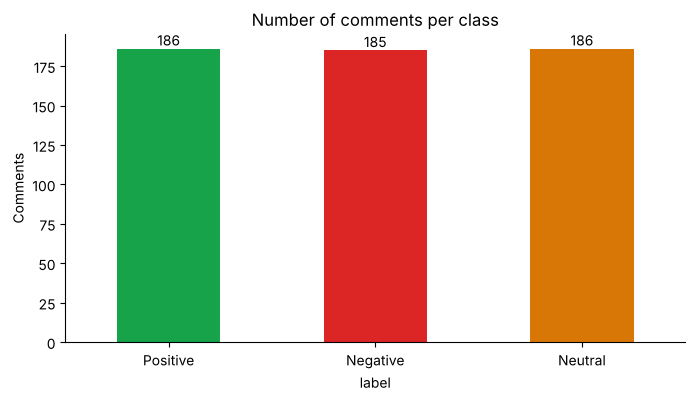

In [3]:
counts = df["label"].value_counts()
print(counts)
ax = counts.reindex(["Positive", "Negative", "Neutral"]).plot.bar(color=[COLORS[l] for l in ["Positive", "Negative", "Neutral"]], rot=0)
ax.set_title("Number of comments per class"); ax.set_ylabel("Comments")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

The three classes are balanced, so the model will not become biased towards one class.

## 3. Look at the raw text (why cleaning is needed)

YouTube comments are messy: capital letters, links, emojis, `@mentions`, timestamps, repeated punctuation, slang.

In [4]:
messy = [
    "This video was AMAZING!!! 😍 https://youtu.be/abc123",
    "@john I didn't like it... waste of time 😡",
    "What song is playing at 3:45? Who's here in 2025?",
    "<b>Great</b> tutorial, thank you so much!!!",
]
for text in messy:
    print(repr(text))

'This video was AMAZING!!! 😍 https://youtu.be/abc123'
"@john I didn't like it... waste of time 😡"
"What song is playing at 3:45? Who's here in 2025?"
'<b>Great</b> tutorial, thank you so much!!!'


## 4. Text cleaning step by step

We apply one rule at a time so you can see exactly what each rule does.

In [5]:
text = "I DIDN'T like it!!! 😡 @john Visit https://youtu.be/abc123 at 3:45 in 2025."
steps = []

def show(label, value):
    steps.append((label, value))

show("0. original", text)

t = text.lower()
show("1. lowercase", t)

t = re.sub(r"(https?://\S+|www\.\S+)", " ", t)
show("2. remove URLs", t)

t = re.sub(r"@\w+", " ", t)
show("3. remove @mentions", t)

t = t.replace("didn't", "did not").replace("n't", " not")
show("4. expand contractions (keep negation!)", t)

t = re.sub(r"\b\d{1,2}:\d{2}\b", " timestamp ", t)
t = re.sub(r"\b(?:19|20)\d{2}\b", " yearnum ", t)
show("5. timestamps and years -> marker words", t)

t = re.sub(r"[^a-z0-9\s]", " ", t)
show("6. remove punctuation and symbols (emoji disappears)", t)

t = re.sub(r"\s+", " ", t).strip()
show("7. remove extra spaces", t)

for label, value in steps:
    print(f"{label:<55} {value!r}")

0. original                                             "I DIDN'T like it!!! 😡 @john Visit https://youtu.be/abc123 at 3:45 in 2025."
1. lowercase                                            "i didn't like it!!! 😡 @john visit https://youtu.be/abc123 at 3:45 in 2025."
2. remove URLs                                          "i didn't like it!!! 😡 @john visit   at 3:45 in 2025."
3. remove @mentions                                     "i didn't like it!!! 😡   visit   at 3:45 in 2025."
4. expand contractions (keep negation!)                 'i did not like it!!! 😡   visit   at 3:45 in 2025.'
5. timestamps and years -> marker words                 'i did not like it!!! 😡   visit   at  timestamp  in  yearnum .'
6. remove punctuation and symbols (emoji disappears)    'i did not like it        visit   at  timestamp  in  yearnum  '
7. remove extra spaces                                  'i did not like it visit at timestamp in yearnum'


Notice step 6: the emoji 😡 was simply deleted. Emojis carry a lot of sentiment in YouTube comments,
so the **project's real cleaning function** converts them to marker words *before* removing symbols. Compare:

In [6]:
sample = "I DIDN'T like it!!! 😡 @john Visit https://youtu.be/abc123 at 3:45 in 2025."
print("Our simple steps  :", t)
print("Project function  :", clean_text(sample))

Our simple steps  : i did not like it visit at timestamp in yearnum
Project function  : not like emojinegative visit timestamp yearnum exclamationmark


The project function also (a) keeps negations like *not*, (b) turns 😡 into `emojinegative`, and
(c) remembers that the comment had `!` or `?` (useful clues: questions are usually Neutral).

## 5. Tokenization

**Tokenization** splits a sentence into small pieces (tokens), usually words.

In [7]:
sentence = "The explanation was excellent and the examples were really helpful"
tokens = sentence.lower().split()
print(tokens)
print("Number of tokens:", len(tokens))

['the', 'explanation', 'was', 'excellent', 'and', 'the', 'examples', 'were', 'really', 'helpful']
Number of tokens: 10


## 6. Stopwords

**Stopwords** are very common words ("the", "is", "and") that carry little meaning.
Removing them makes the important words stand out. **But** we must keep negations: "not good" is very different from "good".

In [8]:
print("Number of stopwords in the project:", len(STOPWORDS))
print("Some stopwords:", sorted(STOPWORDS)[:25], "...")
print("Negations we KEEP:", sorted(NEGATIONS))

tokens = "the explanation was not good but the examples were really helpful".split()
print("\nBefore:", tokens)
print("After :", [t for t in tokens if t not in STOPWORDS])

Number of stopwords in the project: 114
Some stopwords: ['a', 'about', 'above', 'after', 'again', 'against', 'all', 'also', 'am', 'an', 'and', 'any', 'are', 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'by', 'can'] ...
Negations we KEEP: ['cannot', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'without']

Before: ['the', 'explanation', 'was', 'not', 'good', 'but', 'the', 'examples', 'were', 'really', 'helpful']
After : ['explanation', 'not', 'good', 'but', 'examples', 'helpful']


In [9]:
# What happens if we wrongly remove "not"?
wrong = [t for t in tokens if t not in STOPWORDS and t != "not"]
print("If we also dropped 'not':", wrong, " <- sounds positive! The meaning flipped.")

If we also dropped 'not': ['explanation', 'good', 'but', 'examples', 'helpful']  <- sounds positive! The meaning flipped.


## 7. Stemming (demo only)

**Stemming** cuts words to a root form (`running → run`). **Lemmatization** uses a dictionary to return a real word (`better → good`).
Our final model does not need them (TF-IDF with bigrams was enough), but here is a demo using NLTK's Porter stemmer.

In [10]:
try:
    from nltk.stem import PorterStemmer
    stemmer = PorterStemmer()
    words = ["running", "explained", "explanation", "helpful", "studies", "amazing", "loved", "videos"]
    print(pd.DataFrame({"word": words, "stem": [stemmer.stem(w) for w in words]}).to_string(index=False))
    print("\nNote: 'studies' -> 'studi' is not a real word. That is the weakness of stemming.")
except ImportError:
    print("NLTK is not installed. Run:  pip install nltk   (this demo is optional)")

       word    stem
    running     run
  explained explain
explanation  explan
    helpful    help
    studies   studi
    amazing    amaz
      loved    love
     videos   video

Note: 'studies' -> 'studi' is not a real word. That is the weakness of stemming.


## 8. Clean the whole dataset

In [11]:
df["clean"] = df["text"].apply(clean_text)
df = df[df["clean"].str.len() > 0].reset_index(drop=True)
df[["text", "clean", "label"]].sample(8, random_state=3)

,text,clean,label
358,"The video was fine, I guess",video fine guess,Neutral
61,"This is legit the best recipe, my family loved it",legit best recipe family loved,Positive
435,Amazing tutorial 😊 thank you,amazing tutorial emojipositive thank,Positive
396,This is the explanation I was searching for all week,explanation searching week,Positive
157,This is the dumbest thing I have seen today,dumbest thing seen today,Negative
14,"Loved the energy, the host is hilarious and informative",loved energy host hilarious informative,Positive
333,Has anyone tried this on a Raspberry Pi?,anyone tried raspberry pi questionmark,Neutral
534,The video has about two million views,video two million views,Neutral


          words_raw  words_clean
label                           
Negative        7.7          4.6
Neutral         7.1          4.1
Positive        8.1          5.0


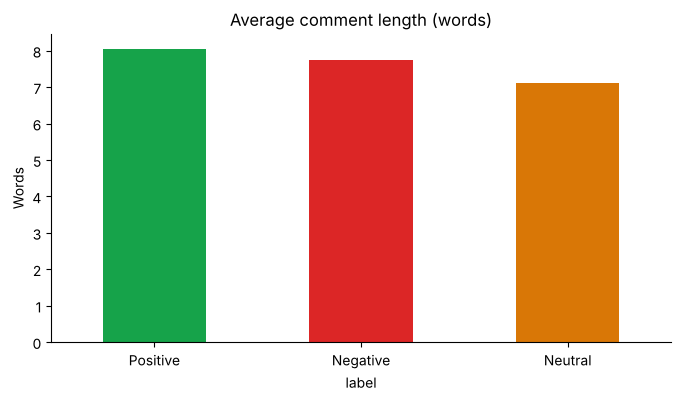

In [12]:
df["words_raw"] = df["text"].str.split().str.len()
df["words_clean"] = df["clean"].str.split().str.len()
print(df.groupby("label")[["words_raw", "words_clean"]].mean().round(1))

ax = df.groupby("label")["words_raw"].mean().reindex(["Positive", "Negative", "Neutral"]).plot.bar(color=[COLORS[l] for l in ["Positive", "Negative", "Neutral"]], rot=0)
ax.set_title("Average comment length (words)"); ax.set_ylabel("Words")
plt.show()

## 9. Turning text into numbers

### 9.1 Bag of Words (word counts)
Each comment becomes a row of counts, one column per word in the vocabulary. Word order is ignored.

In [13]:
mini = ["great video great explanation", "terrible video boring", "what song is this"]
cv = CountVectorizer()
bow = cv.fit_transform(mini)
pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=[f"comment {i+1}" for i in range(3)])

,boring,explanation,great,is,song,terrible,this,video,what
comment 1,0,1,2,0,0,0,0,1,0
comment 2,1,0,0,0,0,1,0,1,0
comment 3,0,0,0,1,1,0,1,0,1


### 9.2 TF-IDF
Counts treat every word equally. **TF-IDF** gives more weight to words that are *special* to a comment.

- **TF** (term frequency) = how often the word appears in this comment
- **IDF** (inverse document frequency) = `log(N / number of comments containing the word)`, which is small for words that appear everywhere
- **TF-IDF = TF × IDF**

A tiny example you can verify by hand:

In [14]:
docs = ["good video", "good tutorial", "bad video"]
N = len(docs)
vocab = sorted({w for d in docs for w in d.split()})

rows = []
for w in vocab:
    df_w = sum(w in d.split() for d in docs)          # in how many documents?
    idf = np.log((1 + N) / (1 + df_w)) + 1              # scikit-learn's smoothed IDF
    rows.append({"word": w, "appears in # docs": df_w, "IDF": round(idf, 3)})
pd.DataFrame(rows)

,word,appears in # docs,IDF
0,bad,1,1.693
1,good,2,1.288
2,tutorial,1,1.693
3,video,2,1.288


In [15]:
tfidf_demo = TfidfVectorizer()
matrix = tfidf_demo.fit_transform(docs)
pd.DataFrame(matrix.toarray().round(3), columns=tfidf_demo.get_feature_names_out(), index=docs)

,bad,good,tutorial,video
good video,0.000,0.707,0.000,0.707
good tutorial,0.000,0.605,0.796,0.000
bad video,0.796,0.000,0.000,0.605


`good` and `video` appear in more than one comment so they get a **lower** weight than rare words like `tutorial` or `bad`.
(scikit-learn also normalises each row so its length is 1.)

### 9.3 TF-IDF on our real dataset (unigrams + bigrams)

In [16]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X = vectorizer.fit_transform(df["clean"])
print("Matrix shape (comments x features):", X.shape)
print("Percentage of cells that are zero :", round(100 * (1 - X.nnz / (X.shape[0] * X.shape[1])), 2), "% (sparse matrix)")
print("Sample features:", list(vectorizer.get_feature_names_out()[500:515]))

Matrix shape (comments x features): (557, 2753)
Percentage of cells that are zero : 99.71 % (sparse matrix)
Sample features: ['delight', 'delivers', 'delivers another', 'demo', 'demo nothing', 'description', 'description working', 'deserve', 'deserve way', 'deserves', 'deserves award', 'deserves brilliant', 'deserves millions', 'deserves way', 'destroyed']


## 10. N-grams

An **n-gram** is a group of n words in a row. **Bigrams** (n = 2) capture short phrases like *not good* or *waste time*,
which single words cannot express.

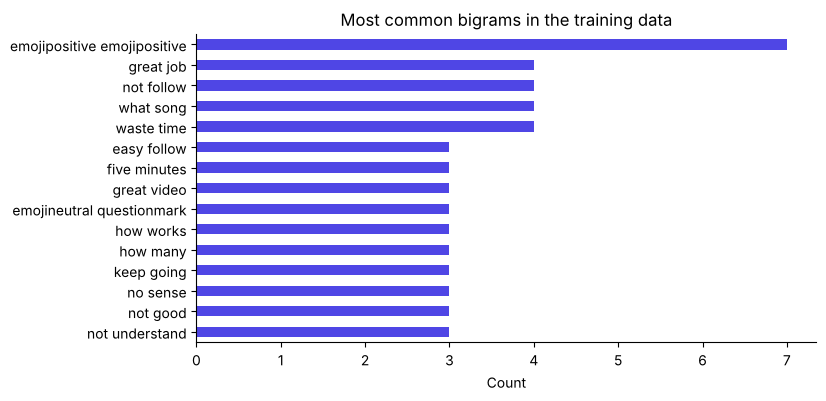

In [17]:
vec_bi = CountVectorizer(ngram_range=(2, 2), min_df=2)
Xb = vec_bi.fit_transform(df["clean"])
bigram_counts = pd.Series(np.asarray(Xb.sum(axis=0)).ravel(), index=vec_bi.get_feature_names_out()).sort_values(ascending=False)
bigram_counts.head(15).iloc[::-1].plot.barh(color="#4f46e5")
plt.title("Most common bigrams in the training data"); plt.xlabel("Count")
plt.show()

## 11. Word insights by sentiment

Which words are most common in positive comments and which in negative ones?
(This is the same idea as the **Comment Insights** section of the web app.)

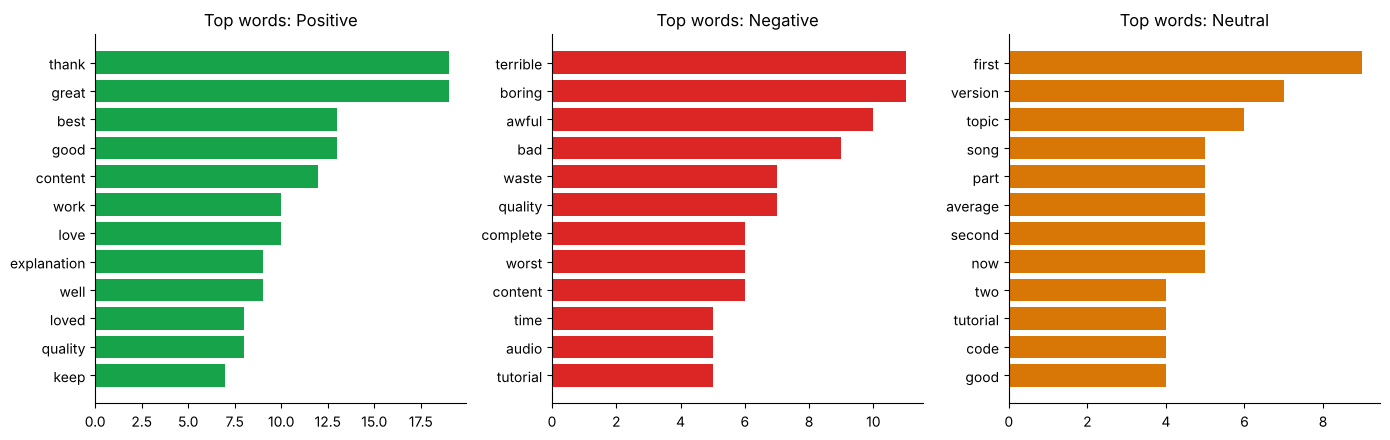

In [18]:
from ml.preprocess import tokenize_for_insights

def top_words(label, n=12):
    counter = Counter()
    for text in df.loc[df["label"] == label, "text"]:
        counter.update(tokenize_for_insights(text))
    return counter.most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, label in zip(axes, ["Positive", "Negative", "Neutral"]):
    words = top_words(label)
    ax.barh([w for w, _ in words][::-1], [c for _, c in words][::-1], color=COLORS[label])
    ax.set_title(f"Top words: {label}")
plt.tight_layout(); plt.show()

### Words that best separate Positive from Negative

In [19]:
pos_c = Counter(); neg_c = Counter()
for t in df.loc[df.label == "Positive", "text"]: pos_c.update(tokenize_for_insights(t))
for t in df.loc[df.label == "Negative", "text"]: neg_c.update(tokenize_for_insights(t))

rows = []
for w in set(pos_c) | set(neg_c):
    p, n = pos_c[w], neg_c[w]
    if p + n >= 4:
        rows.append({"word": w, "positive": p, "negative": n, "log_ratio": np.log((p + 1) / (n + 1))})
ratio = pd.DataFrame(rows).sort_values("log_ratio")
print("Most NEGATIVE words:", ", ".join(ratio.head(10)["word"]))
print("Most POSITIVE words:", ", ".join(ratio.tail(10)["word"][::-1]))

Most NEGATIVE words: terrible, awful, bad, waste, worst, complete, boring, audio, hate, annoying
Most POSITIVE words: thank, great, best, love, well, perfect, keep, amazing, job, super


## 12. Try the cleaning function on your own comment

Change the text and run the cell.

In [20]:
my_comment = "Honestly this was NOT helpful, I wasted 20 minutes 😡 https://example.com"

print("Original :", my_comment)
print("Cleaned  :", clean_text(my_comment))
print("Tokens   :", clean_text(my_comment).split())

Original : Honestly this was NOT helpful, I wasted 20 minutes 😡 https://example.com
Cleaned  : honestly not helpful wasted 20 minutes emojinegative
Tokens   : ['honestly', 'not', 'helpful', 'wasted', '20', 'minutes', 'emojinegative']


## 13. Summary

| Step | What it does | Why |
|---|---|---|
| Lowercase | `Great` → `great` | same word, same token |
| Remove URLs / mentions | deletes links and `@names` | no sentiment value |
| Expand contractions | `didn't` → `did not` | keeps negation |
| Emoji → marker words | 😡 → `emojinegative` | emojis show emotion |
| Remove punctuation | `!!!` removed | cleaner tokens |
| Stopword removal | removes `the`, `is` ... | focus on meaningful words |
| TF-IDF (1-2 grams) | text → weighted numbers | machine learning needs numbers |

**Next:** open `2_Machine_Learning.ipynb` to train and evaluate the classifier on these TF-IDF features.